## Superstore Data Analysis
### Data Cleaning, Advanced Analysis and Business Insights using Pandas

**Project 2 | Devsil**

---

### Objective
Perform structured data cleaning, exploratory data analysis (EDA), and
advanced business analysis on the Superstore dataset using Pandas, and
generate actionable business insights.

## Table of Tasks
1. Data Loading
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Advanced Analysis
6. Visualization
7. Final Insights and Conclusion

In [40]:
# import all the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Step 1: Data loading

In [41]:
# load the dataset
df= pd.read_csv('superstore.csv',encoding='latin1')

In [42]:
# first five rows and columns of the dataset
print(df.head(5))
print(df.tail(5))
# name of the columns in the dataset
print(df.columns)
# data types of the columns and information about the dataset
print(df.dtypes)
print(df.info())
# rows and columns of the dataset
print(df.shape)



   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

## 2. Data Cleaning

### Objective
Prepare the dataset for analysis by cleaning and validating the data.

### Tasks
1. Check missing values using `.isnull().sum()`
2. Handle missing values
3. Check and remove duplicate records
4. Convert `Order Date` and `Ship Date` columns into datetime format
5. Verify the cleaned dataset

#### 2.1:

In [43]:
# checking for null values in the dataset
(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64



**Observation:**
The `.isnull().sum()` output shows **0 missing values** in all columns.
The dataset is complete, so no rows needed to be dropped and no values
needed to be filled (imputed).

#### 2.2:

In [44]:
# handling the missing values in the dataset
print("missing values: ", df.isnull().sum().sum())

missing values:  0


**Observation:**
The dataset had 0 missing values, so no rows were removed.

#### 2.3:

In [45]:
# check and remove duplicate values in the dataset
df.duplicated().sum()

np.int64(0)

**Observation :** ther is no duplicate values in the dataset

#### 2.4:

In [46]:
# now Convert `Order Date` and `Ship Date` columns into datetime format
print("Converting Order Date to datetime...")
df['Order Date'] = pd.to_datetime(df['Order Date'])



Converting Order Date to datetime...


In [47]:
print("Converting Ship Date to datetime...")
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

Converting Ship Date to datetime...


In [48]:
df[['Order Date', 'Ship Date']].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

**Observation:** Order date and ship date columns are now in datetime format.

#### 2.5:

In [49]:
# now verifing the cleaned dataset
# Final shape of the cleaned dataset
print("Shape:", df.shape)

# Missing values and duplicates
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())

# Data types of all columns
df.info()

Shape: (9994, 21)
Missing values : 0
Duplicate rows : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9

## 3. Exploratory Data Analysis (EDA)

### Objective
Understand the main patterns in the data by analyzing Sales, Profit and
Quantity, grouping the data by key categories, and identifying
top-performing and loss-making areas.

### Tasks
1. Analyze Sales, Profit and Quantity
2. Group by Category, Sub-Category, Region and Segment
3. Identify top-performing and loss-making areas

#### 3.1:

In [50]:
# analyzing sales , profit and quantity columns
df[['Sales', 'Profit', 'Quantity']].describe()

,Sales,Profit,Quantity
count,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,3.789574
std,623.245101,234.260108,2.225110
min,0.444000,-6599.978000,1.000000
25%,17.280000,1.728750,2.000000
50%,54.490000,8.666500,3.000000
75%,209.940000,29.364000,5.000000
max,22638.480000,8399.976000,14.000000


In [51]:
# Overall business totals
print("Total Sales   :", round(df["Sales"].sum(), 2))
print("Total Profit  :", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())

Total Sales   : 2297200.86
Total Profit  : 286397.02
Total Quantity: 37873


**Observation:**
- Total Sales: **2,297,200.86**
- Total Profit: **286,397.02**
- Total Quantity Sold: **37,873 units**
- Overall profit margin is about **12.47%** (286,397.02 / 2,297,200.86), which means the business earns roughly 12 cents of profit on every dollar of sales.

### 3.2 Group By Analysis

Group the data by Category, Sub-Category, Region and Segment to compare
Sales, Profit and Quantity across each group.

### Step A: Category wise

In [52]:
# groping the data category wise and calculating the total sales, profit and quantity
df.groupby('Category')[['Sales', 'Profit', 'Quantity']].sum().round(2)

,Sales,Profit,Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


**Observation (Category):**
- **Technology** is the most profitable category with a profit of 145,454.95 on sales of 836,154.03 (about 17.4% margin).
- **Office Supplies** earns a profit of 122,490.80 (about 17.0% margin) and sells the most units (22,906).
- **Furniture** has high sales (741,999.80) but only 18,451.27 profit (about 2.5% margin), so it is the weakest category in terms of profitability.

### Step 2: Sub Category Wise

In [53]:
# grouping the data sub-category wise and calculating the total sales, profit and quantity
df.groupby('Sub-Category')[['Sales', 'Profit', 'Quantity']].sum().round(2)

,Sales,Profit,Quantity
Sub-Category,,,
Accessories,167380.32,41936.64,2976
Appliances,107532.16,18138.01,1729
Art,27118.79,6527.79,3000
Binders,203412.73,30221.76,5974
Bookcases,114880.00,-3472.56,868
Chairs,328449.10,26590.17,2356
Copiers,149528.03,55617.82,234
Envelopes,16476.40,6964.18,906
Fasteners,3024.28,949.52,914


**Observation (Sub-Category):**
- **Top profit sub-categories:** Copiers (55,617.82), Phones (44,515.73), Accessories (41,936.64), Paper (34,053.57) and Binders (30,221.76).
- **Loss-making sub-categories:** Tables (-17,725.48), Bookcases (-3,472.56) and Supplies (-1,189.10).
- **Tables** has sales of 206,965.53 but still makes a loss, so it needs a review of discounts and pricing.
- **Machines** has high sales (189,238.63) but a very low profit (3,384.76), which shows weak margins.
- **Copiers** sold only 234 units but earned the highest profit, so it is a high-value product.

####  Region wise



In [54]:
# groupong the data by region wise and calculating the total sales, profit and quantity
df.groupby('Region')[['Sales', 'Profit', 'Quantity']].sum().round(2)

,Sales,Profit,Quantity
Region,,,
Central,501239.89,39706.36,8780
East,678781.24,91522.78,10618
South,391721.90,46749.43,6209
West,725457.82,108418.45,12266


**Observation (Region):**
- **West** is the best region with the highest sales (725,457.82) and profit (108,418.45), about a 14.9% margin.
- **East** is second with sales of 678,781.24 and profit of 91,522.78 (about 13.5% margin).
- **South** has the lowest sales (391,721.90) but a decent margin of about 11.9%.
- **Central** has sales of 501,239.89 but the lowest profit (39,706.36) and the weakest margin (about 7.9%), so it needs a review of discounts and costs.

#### Segment wise

In [55]:
# now we will analyze the data segment wise and calculate the total sales, profit and quantity
df.groupby('Segment')[['Sales', 'Profit', 'Quantity']].sum().round(2)

,Sales,Profit,Quantity
Segment,,,
Consumer,1161401.34,134119.21,19521
Corporate,706146.37,91979.13,11608
Home Office,429653.15,60298.68,6744


**Observation (Segment):**
- **Consumer** is the largest segment with sales of 1,161,401.34 (about 50.6% of total sales) and the highest profit (134,119.21), but its margin is the lowest (about 11.5%).
- **Corporate** has sales of 706,146.37 and profit of 91,979.13 (about 13.0% margin).
- **Home Office** is the smallest segment (sales 429,653.15) but has the best margin (about 14.0%).
  

## Top Perfomrmng and Los Area:  

In [56]:
# Top 5 sub-categories by Profit
sub_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).round(2)
sub_profit.head(5)

Sub-Category
Copiers        55617.82
Phones         44515.73
Accessories    41936.64
Paper          34053.57
Binders        30221.76
Name: Profit, dtype: float64

In [57]:
# top 5 sub-categories by loss
sub_loss = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=True).round(2)
sub_loss.head(3)

Sub-Category
Tables      -17725.48
Bookcases    -3472.56
Supplies     -1189.10
Name: Profit, dtype: float64

**Observation (Top and Loss-Making Sub-Categories):**
- **Top 5 by profit:** Copiers (55,617.82), Phones (44,515.73), Accessories (41,936.64), Paper (34,053.57) and Binders (30,221.76).
- **Loss-making:** Tables (-17,725.48), Bookcases (-3,472.56) and Supplies (-1,189.10).
- Tables alone loses more than the other two combined, so it is the biggest problem area.
- Tables and Bookcases both belong to the Furniture category, which explains why Furniture has a very low profit margin (about 2.5%).

In [58]:
# top 5 sub-categories by States
states = df.groupby("State")["Profit"].sum().sort_values(ascending=False).round(2)
states.head(5)

State
California    76381.39
New York      74038.55
Washington    33402.65
Michigan      24463.19
Virginia      18597.95
Name: Profit, dtype: float64

**Observation (Top 5 States by Profit):**
- **California** (76,381.39) and **New York** (74,038.55) are the two most profitable states, contributing about 26.7% and 25.9% of total profit.
- Together, these two states generate about **52.5%** of the company's total profit, which shows a strong dependence on just two states.
- Washington (33,402.65), Michigan (24,463.19) and Virginia (18,597.95) complete the top 5.
- The top 5 states together contribute about **79.2%** of total profit.

In [59]:
# States with negative total Profit
state_profit = df.groupby("State")["Profit"].sum().sort_values(ascending=True).round(2)
state_profit[state_profit < 0]

State
Texas            -25729.36
Ohio             -16971.38
Pennsylvania     -15559.96
Illinois         -12607.89
North Carolina    -7490.91
Colorado          -6527.86
Tennessee         -5341.69
Arizona           -3427.92
Florida           -3399.30
Oregon            -1190.47
Name: Profit, dtype: float64

**Observation (Loss-Making States):**
- **10 states** are loss-making, with a combined loss of about **98,246.74**.
- **Texas** (-25,729.36) is the biggest problem state, about 26% of the total loss, followed by Ohio (-16,971.38), Pennsylvania (-15,559.96) and Illinois (-12,607.89).
- These top 4 states together account for about **72%** of the total loss, so fixing a few states would remove most of the problem.
- Oregon (-1,190.47) and Florida (-3,399.30) have small losses and are close to break-even.
- Several large states lose money while California and New York earn the most profit, so profitability varies a lot by state.

# 4. Feature Engineering

## Objective
Create new useful columns from the existing data to support deeper analysis.

## Tasks
1. Create Profit Ratio = Profit / Sales
2. Extract Year and Month from Order Date
3. Create additional useful columns

In [60]:
# Profit Ratio: profit earned per unit of sales
df["Profit Ratio"] = df["Profit"] / df["Sales"]



In [61]:
# Check the new column
df[["Sales", "Profit", "Profit Ratio"]].head()

,Sales,Profit,Profit Ratio
0,261.9600,41.9136,0.1600
1,731.9400,219.5820,0.3000
2,14.6200,6.8714,0.4700
3,957.5775,-383.0310,-0.4000
4,22.3680,2.5164,0.1125


**Observation:**
The new `Profit Ratio` column was created successfully. For example, the first order earned a 16% profit (0.16), while the fourth order has a ratio of -0.40, meaning it lost 40 cents on every dollar of sales. A negative Profit Ratio identifies loss-making orders.

In [62]:
# Extract Year and Month from `Order Date` for time-based analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month



In [63]:
# Month name (Jan, Feb, ...) for readable charts
df["Month Name"] = df["Order Date"].dt.strftime("%b")

In [64]:
# now cheking new columns
df[["Order Date", "Year", "Month", "Month Name"]].head()

,Order Date,Year,Month,Month Name
0,2016-11-08,2016,11,Nov
1,2016-11-08,2016,11,Nov
2,2016-06-12,2016,6,Jun
3,2015-10-11,2015,10,Oct
4,2015-10-11,2015,10,Oct


In [65]:
# sales of every years
df.groupby("Year")["Sales"].sum()

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

In [66]:
# sales of every months
df.groupby("Month")["Sales"].sum()

Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64

**Observation:**
`Year`, `Month` and `Month Name` were extracted from `Order Date`. For example, the first order was placed in November 2016 (Year = 2016, Month = 11, Month Name = Nov). The data covers different years, which allows yearly and monthly trend analysis in the next phases.

In [67]:
# creating additional usefull columns
# Shipping Days: days between order date and ship date
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Profit Status: label each order as Profit or Loss
df["Profit Status"] = df["Profit"].apply(lambda x: "Profit" if x > 0 else "Loss")

# Check the new columns
df[["Order Date", "Ship Date", "Shipping Days", "Profit", "Profit Status"]].head()

,Order Date,Ship Date,Shipping Days,Profit,Profit Status
0,2016-11-08,2016-11-11,3,41.9136,Profit
1,2016-11-08,2016-11-11,3,219.5820,Profit
2,2016-06-12,2016-06-16,4,6.8714,Profit
3,2015-10-11,2015-10-18,7,-383.0310,Loss
4,2015-10-11,2015-10-18,7,2.5164,Profit


**Observation:**
- `Shipping Days` was calculated as Ship Date minus Order Date. In the sample rows, orders took between 3 and 7 days to ship.
- `Profit Status` labels each order as Profit or Loss. For example, the fourth order lost 383.03 and is marked as Loss, while the others are marked as Profit.
- Both columns will be used in the advanced analysis.

#### Now to check new columns and sve all the files :

In [68]:
# Show all columns
print(df.columns.tolist())

# Check shape
print("Shape:", df.shape)

# Save the updated cleaned dataset
df.to_csv("cleaned_superstore.csv", index=False)
print("Cleaned dataset saved.")

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Profit Ratio', 'Year', 'Month', 'Month Name', 'Shipping Days', 'Profit Status']
Shape: (9994, 27)
Cleaned dataset saved.


**Summary of Phase 4:**
Six new columns were created: Profit Ratio, Year, Month, Month Name, Shipping Days and Profit Status. The dataset now has 9,994 rows and 27 columns, and was saved as `cleaned_superstore.csv`.

# 5. Advanced Analysis

## Objective
Investigate the causes behind profit and loss by analyzing loss-making products, regional profitability, time trends, and the relationship between discount and profit.

## Tasks
1. Identify loss-making products
2. Region-wise profitability analysis
3. Monthly and yearly trends
4. Discount vs Profit relationship

In [69]:
# lose making products
product_profit=df.groupby("Product Name")["Profit"].sum().sort_values(ascending=True).round(2)

print("Number of loss-making products:", (product_profit < 0).sum())

Number of loss-making products: 299


**Observation (Loss-Making Products):**
A total of **299 individual products** have a negative total profit. These products reduce overall profitability and should be reviewed for pricing and discount decisions.

In [70]:
# region wise profitability analysis
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False).round(2)
print("Region-wise Profitability:\n", region_profit)

Region-wise Profitability:
 Region
West       108418.45
East        91522.78
South       46749.43
Central     39706.36
Name: Profit, dtype: float64


**Observation (Region-wise Profitability):**
- **West** is the most profitable region (108,418.45), contributing about 37.9% of total profit, with the best margin (about 14.9%).
- **East** is second (91,522.78, about 32.0% of total profit) with a margin of about 13.5%.
- **South** earns 46,749.43 (about 16.3% of total profit) with a margin of about 11.9%.
- **Central** is the weakest region: the lowest profit (39,706.36, about 13.9% of total) and the lowest margin (about 7.9%), even though its sales (501,239.89) are higher than South's (391,721.90).
- West and East together generate about **70%** of the company's total profit.

In [75]:
# now dealing with monthly and yearly trend analysis of sales and profit
# total sales and profit for each year
yearly_sales = df.groupby("Year")["Sales"].sum().round(2)
yearly_profit = df.groupby("Year")["Profit"].sum().round(2)

# total margin for each year
yearly_margin = (yearly_profit / yearly_sales * 100).round(2)

# year-over-year sales groth
yearly_sales_growth = yearly_sales.pct_change().round(4) * 100

# combine everything in one table to display
yearly = pd.DataFrame({
    "Sales": yearly_sales,
    "Profit": yearly_profit,
    "Profit Margin %": yearly_margin,
    "Sales Growth %": yearly_sales_growth
})
yearly


,Sales,Profit,Profit Margin %,Sales Growth %
Year,,,,
2014,484247.50,49543.97,10.23,NaN
2015,470532.51,61618.60,13.10,-2.83
2016,609205.60,81795.17,13.43,29.47
2017,733215.26,93439.27,12.74,20.36


**Observation (Yearly Trend):**
- Sales grew from 484,247.50 in 2014 to 733,215.26 in 2017, an increase of about **51%**. Profit grew from 49,543.97 to 93,439.27, an increase of about **89%**.
- **2015** was the only year with a sales decline (-2.83%), but profit still rose by about 24% because the margin improved from 10.23% to 13.10%.
- **2016** had the strongest growth: sales +29.47% and profit +32.7%.
- **2017** is the best year in sales (733,215.26) and profit (93,439.27), but sales growth slowed to 20.36% and profit growth to about 14.2%.
- The profit margin dipped from 13.43% in 2016 to 12.74% in 2017, so profit grew more slowly than sales that year.

In [74]:
# Total Sales and Profit for each Month (1 to 12), 
monthly = df.groupby("Month")[["Sales", "Profit"]].sum().round(2)

# Add month names 
monthly["Month Name"] = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

monthly

,Sales,Profit,Month Name
Month,,,
1,94924.84,9134.45,Jan
2,59751.25,10294.61,Feb
3,205005.49,28594.69,Mar
4,137762.13,11587.44,Apr
5,155028.81,22411.31,May
6,152718.68,21285.80,Jun
7,147238.10,13832.66,Jul
8,159044.06,21776.94,Aug
9,307649.95,36857.48,Sep


**Observation (Monthly Trend):**
- **November** has the highest sales (352,461.07), followed by December (325,293.50) and September (307,649.95).
- **December** has the highest profit (43,369.19), followed by September (36,857.48) and November (35,468.43).
- September to December together generate about **51.6%** of total sales, which shows strong year-end seasonality.
- **February** has the lowest sales (59,751.25) and **January** the lowest profit (9,134.45).
- Profit margin does not follow sales. November has the highest sales but a margin of only about 10.1%, while February has the lowest sales but a margin of about 17.2%.

### 5.4 Discount vs Profit

Analyze how the discount given on an order affects its profit.

In [77]:
# Correlation between Discount and Profit (-1 to +1)
print("Correlation (Discount vs Profit):", round(df["Discount"].corr(df["Profit"]), 3))

Correlation (Discount vs Profit): -0.219


**Observation (Discount vs Profit):**
- The correlation between Discount and Profit is **-0.219**, a weak but clear negative relationship: higher discounts tend to go with lower profit.
- The table shows a sharp turning point. At discounts up to **20%**, every level is profitable (combined profit of about 421,773). From **30% upwards**, every level is loss-making.
- Orders with a discount of 30% or more number **1,393** (about 13.9% of all orders) and lose about **135,376** in total. This loss wipes out a large part of the profit earned elsewhere.
- Orders with **no discount** earn an average profit of 66.90 per order, while orders with a **20% discount** earn only 24.70, so even a moderate discount cuts profit per order by about 63%.
- The **50% discount** level has the worst average loss per order (-310.70), and the **70% discount** level has the largest total loss (-40,075.36).
- The 45% level shows an average loss of -226.65, but it has only 11 orders, so it is a very small sample.

In [78]:
# For each discount level: number of orders, total profit and average profit per order
df.groupby("Discount")["Profit"].agg(["count", "sum", "mean"]).round(2)

,count,sum,mean
Discount,,,
0.00,4798,320987.60,66.90
0.10,94,9029.18,96.06
0.15,52,1418.99,27.29
0.20,3657,90337.31,24.70
0.30,227,-10369.28,-45.68
0.32,27,-2391.14,-88.56
0.40,206,-23057.05,-111.93
0.45,11,-2493.11,-226.65
0.50,66,-20506.43,-310.70


**Summary of Phase 5:**
- 299 individual products are loss-making.
- West and East generate most of the profit, while Central has the weakest margin.
- Sales and profit grew strongly from 2014 to 2017, with sales peaking in November and December.
- Discounts above 20% consistently cause losses, making discount policy the key area for improvement.

# 6. Visualization

## Objective
Present the main findings visually using charts.

## Charts
1. Sales trend over time
2. Profit by category
3. Correlation heatmap
4. Region comparison charts

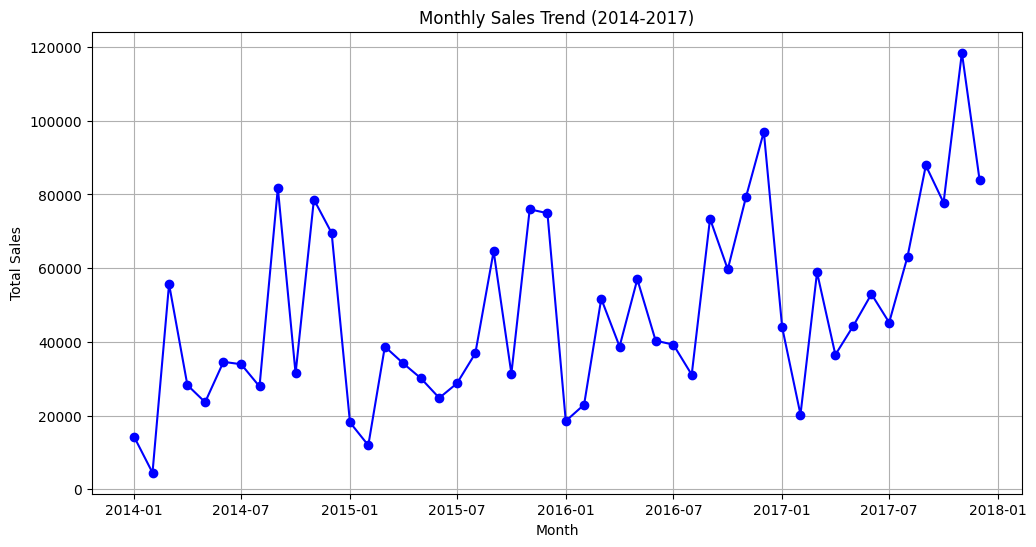

In [81]:
# total sales for each calender month (1 to 12),
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()


# line chart for monthly sales
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', linestyle='-', color='b')
plt.title("Monthly Sales Trend (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid()
plt.show()


**Observation (Sales Trend):**
- Sales show a clear **upward trend** over the four years. The peaks grow from about 82,000 in 2014 to about 118,000 in November 2017.
- There is strong **seasonality**: sales rise every year from September to December, with the highest points in November and December (for example, about 97,000 in December 2016 and about 118,000 in November 2017).
- **January and February** are the weakest months in every year, with sales often below 20,000 (the lowest point is in February 2014, about 5,000).
- Sales are **volatile** from month to month, with sharp jumps and drops rather than a smooth line.
- The 2015 line sits lower than 2014 in the first half, which matches the 2.83% sales decline seen in the yearly table.

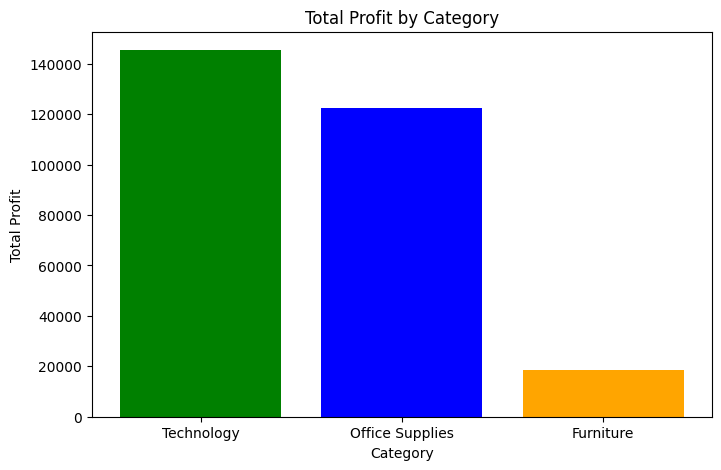

In [82]:
# now we will draw total profit for each category
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False).round(2)

# bar chart for category-wise profit
plt.figure(figsize=(8, 5))
plt.bar(category_profit.index, category_profit.values, color=['green', 'blue', 'orange'])
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()

**Observation (Profit by Category):**
- **Technology** is the most profitable category (145,454.95), followed closely by **Office Supplies** (122,490.80).
- **Furniture** earns only 18,451.27, which is about **13%** of Technology's profit and only about **6.4%** of the company's total profit.
- Technology and Office Supplies together generate about **93.6%** of total profit.
- Furniture has the highest-selling pressure but the weakest return, which links back to the loss-making Tables and Bookcases sub-categories found in Section 3.3.

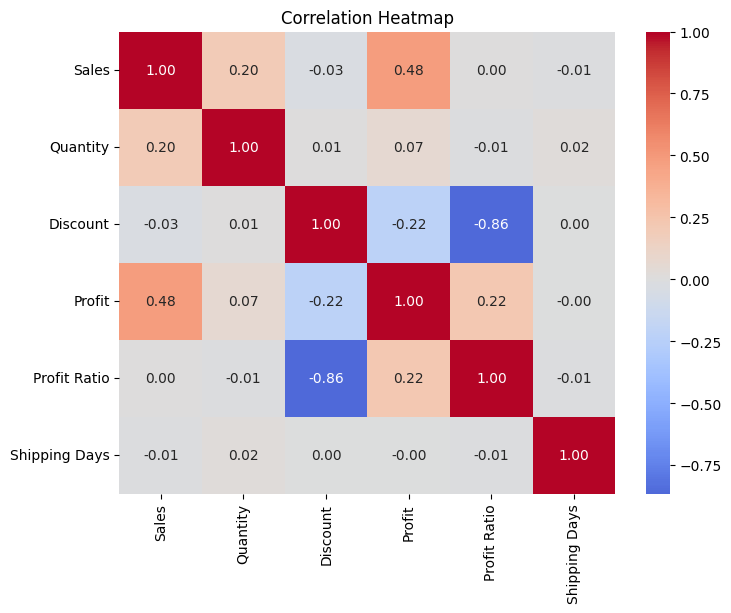

In [83]:
# Select the main numeric columns
num_cols = ["Sales", "Quantity", "Discount", "Profit", "Profit Ratio", "Shipping Days"]

# Correlation matrix
corr = df[num_cols].corr()

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Observation (Correlation Heatmap):**
- **Discount and Profit Ratio (-0.86)** is the strongest relationship in the data: as discount increases, the profit margin falls sharply.
- **Discount and Profit (-0.22)** is a weak negative relationship. It is weaker than -0.86 because Profit is in absolute amounts and also depends on the order size, while Profit Ratio does not.
- **Sales and Profit (0.48)** is a moderate positive relationship: larger orders tend to earn more profit, but not always.
- **Sales and Profit Ratio (0.00)** shows that bigger orders do not automatically have better margins.
- **Sales and Quantity (0.20)** is weak, so the number of units does not explain the sales value well (prices differ a lot between products).
- **Shipping Days** has almost zero correlation with every column, so shipping time does not affect sales or profit.

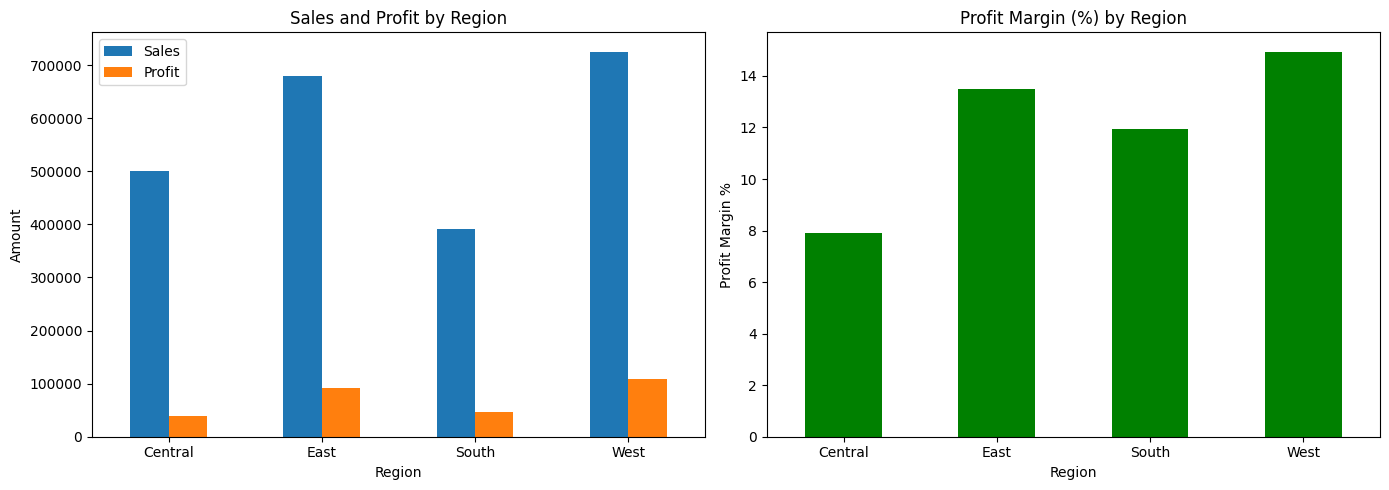

In [84]:
# Total Sales and Profit for each Region
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Profit Margin %"] = region["Profit"] / region["Sales"] * 100

# Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Sales and Profit by Region
region[["Sales", "Profit"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Sales and Profit by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Amount")
axes[0].tick_params(axis="x", rotation=0)

# Chart 2: Profit Margin by Region
region["Profit Margin %"].plot(kind="bar", ax=axes[1], color="green")
axes[1].set_title("Profit Margin (%) by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Profit Margin %")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observation (Region Comparison):**
- **West** has the highest sales (about 725,000) and the highest profit (about 108,000), and also the best margin (about 14.9%).
- **East** is second in sales (about 679,000) and profit (about 92,000), with a margin of about 13.5%.
- **Central** has higher sales (about 501,000) than South (about 392,000), but its profit (about 40,000) is lower than South's (about 47,000). Its margin (about 7.9%) is the weakest of all regions.
- **South** is the smallest region by sales, but its margin (about 11.9%) is better than Central's.
- Bigger sales do not guarantee better profitability, as the Central region shows.

# 7. Final Insights and Conclusion

## Key Insights

**Overall performance**
- Total sales are 2,297,200.86 and total profit is 286,397.02, an overall margin of about 12.5%.
- Sales grew about 51% and profit about 89% between 2014 and 2017.

**Products and categories**
- Technology (145,454.95) and Office Supplies (122,490.80) generate about 93.6% of total profit.
- Furniture earns only 18,451.27 on sales of 741,999.80, because Tables (-17,725.48) and Bookcases (-3,472.56) are loss-making. Supplies (-1,189.10) is the third loss-making sub-category.
- 299 individual products are loss-making.

**Regions and states**
- West and East generate about 70% of total profit.
- Central has the weakest margin (about 7.9%).
- California and New York contribute about 52.5% of total profit, while 10 states are loss-making, led by Texas (-25,729.36), Ohio (-16,971.38), Pennsylvania (-15,559.96) and Illinois (-12,607.89).

**Time trends**
- Sales peak every year from September to December, and are weakest in January and February.

**Discount**
- Discount and Profit Ratio are strongly negatively correlated (-0.86).
- Every discount level of 30% or more is loss-making. These orders (1,393) lose about 135,376 in total.


## Conclusion
The business is growing and profitable overall, but profit is held back by heavy discounting and a few loss-making products and states. Controlling discounts is the single most effective step to improve profitability.